# Credit Default Prediction - Exploratory Data Analysis

## Project overview
This project aims to predict wether a credit card client will default on their payment in the following month.
**Dataset:** 
Default of Credit Card Clients (UCI)
- 30,000 observations
- 23 input features
- Target variable: Y (0 = no default, 1 = default)

**Objective:**
Explore the dataset, assess data quality and investigate potential relationships between client characteristics and credit default.

## 1. Dataset loading and initial exploration

In [1]:
from ucimlrepo import fetch_ucirepo

#uploading dataset from UCI:
dataset = fetch_ucirepo(id=350)

X = dataset.data.features
y = dataset.data.targets
print("Dataset successfully loaded")

Dataset successfully loaded


In [2]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30000, 23)
y shape: (30000, 1)


In [3]:
#renaming columns to names with meaning
column_mapping = {"X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION", "X4": "MARRIAGE", "X5": "AGE", "X6": "PAY_0", "X7": "PAY_2", "X8": "PAY_3", "X9": "PAY_4", "X10": "PAY_5", "X11": "PAY_6", "X12": "BILL_AMT1", "X13": "BILL_AMT2", "X14": "BILL_AMT3", "X15": "BILL_AMT4", "X16": "BILL_AMT5", "X17": "BILL_AMT6", "X18": "PAY_AMT1", "X19": "PAY_AMT2", "X20": "PAY_AMT3", "X21": "PAY_AMT4", "X22": "PAY_AMT5", "X23": "PAY_AMT6"}
X = X.rename(columns=column_mapping)

#displaying only useful columns
#(monetary amounts are stated in New Taiwan dollars)
display(X[["LIMIT_BAL", "AGE", "PAY_0", "BILL_AMT1", "PAY_AMT1"]].head())

,LIMIT_BAL,AGE,PAY_0,BILL_AMT1,PAY_AMT1
0,20000,24,2,3913,0
1,120000,26,-1,2682,0
2,90000,34,0,29239,1518
3,50000,37,0,46990,2000
4,50000,57,-1,8617,2000


In [4]:
display(y.head())
print("Number of clients in each class:")
print(y.iloc[:, 0].value_counts())

,Y
0,1
1,1
2,0
3,0
4,0


Number of clients in each class:
Y
0    23364
1     6636
Name: count, dtype: int64


## 2. Data quality assessment

In [5]:
#starting exploratory data analysis
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   30000 non-nu

In [6]:
#checking if theyre any missing val
X.isna().sum()

LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
dtype: int64

In [7]:
#summary stats for num features(monetary amounts are stated in New Taiwan dollars)
display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


## Initial data quality checks
- the data set contains 30k observations and 23 features
- all features are stored as int
- no missing values 
- some categorical data contain undocumented codes
- some bill amounts are negative and require checking

### Categorical Feature Inspection

We examine the unique values and their frequencies
in EDUCATION, MARRIAGE, and PAY_0 to identify
potential data quality issues.

In [8]:
#considering categorical features
#checking how often do unusual values appear
for column in ["EDUCATION", "MARRIAGE", "PAY_0"]:
    print(f"\n{column}")
    print(X[column].value_counts().sort_index())


EDUCATION
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

PAY_0
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


### Categorical features: initial findings
- Education contains undocumented codes: 0, 5 ,6. Those codes affect 345 observations.
- Marriage contains one undocumented code - 0. It affects 54 observations.
- PAY_0 contains additional values: -2 and 0. They are not explained in UCI documentation.

We keep original values during EDA and investigate appropriate encoding during preprocessing. 

## 3. Feature Distribution Analysis

We examine the distributions of selected client
characteristics before investigating their relationship with credit default.

### 3.1 Age Distribution

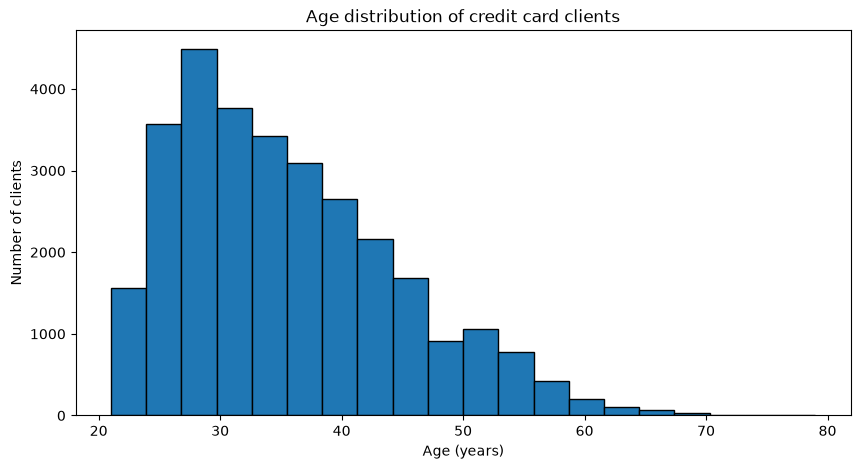

In [9]:
import matplotlib.pyplot as plt
#now we are plotting histogramm of age distribution
plt.figure(figsize = (10, 5))
plt.hist(X["AGE"], bins=20, edgecolor = "black")
plt.title("Age distribution of credit card clients")
plt.xlabel("Age (years)")
plt.ylabel("Number of clients")
plt.show()

### Observations of age distribution
- Most clients are concentrated between approximately
  25 and 40 years old.
- The distribution peaks around ages 28 and 30.
- The age distribution is right skewed, with fewer
  observations among older clients.
- The dataset contains clients aged 21 to 79.

**Conclusion:**
Younger adults are more heavily represented in this
dataset. However, this distribution alone does not tell us whether age is associated with credit default.

### 3.2 Credit Limit Distribution

Mean credit limit: 167,484.32 NTD
Median credit limit: 140,000.00 NTD


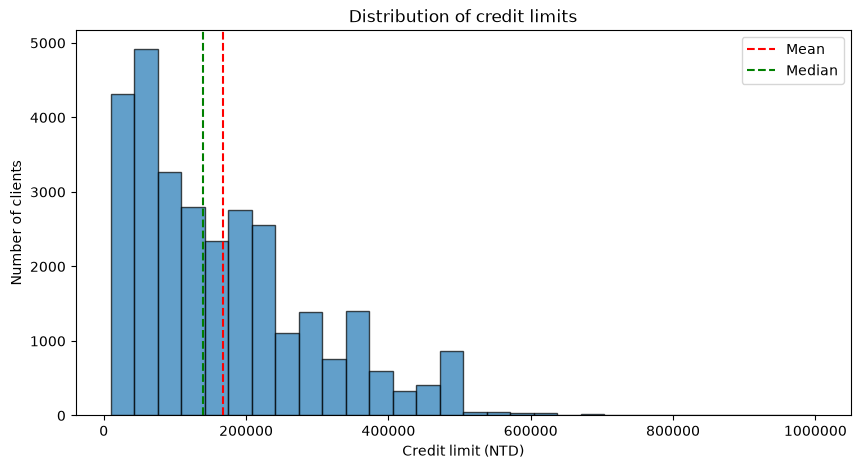

In [10]:
#mean and median credit limits
mean_limit = X["LIMIT_BAL"].mean()
median_limit = X["LIMIT_BAL"].median()
print(f"Mean credit limit: {mean_limit:,.2f} NTD")
print(f"Median credit limit: {median_limit:,.2f} NTD")

#plotting credit limit distribution
plt.figure(figsize=(10, 5))
plt.hist(X["LIMIT_BAL"], bins=30, edgecolor="black", alpha=0.7)

#adding mean and median lines
plt.axvline(mean_limit, color="red", linestyle="--", label="Mean")
plt.axvline(median_limit, color="green", linestyle="--", label="Median")

plt.title("Distribution of credit limits")
plt.xlabel("Credit limit (NTD)")
plt.ylabel("Number of clients")

plt.ticklabel_format(style="plain", axis="x")
plt.legend()
plt.show()

#### Observation of credit limit distribution
- Most clients have relatively low to moderate credit limits.
- The highest concentration is approximately between 20,000 and 200,000 NTD.
- The distribution is right - skewed, with a long tail extending toward higher credit limits.
- The mean credit limit (167,484 NTD) is higher than the median (140,000 NTD).

**Conclusion:**

Credit limits are not symmetrically distributed.
A relatively small number of clients with high credit limits contribute to the difference between the mean and median.

## 4. Train/Test Split

We split the dataset into training and test sets before checking relationships with the target.

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y["Y"], test_size=0.2, random_state=42, stratify=y["Y"])

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 24000
Test samples: 6000



## 5. Relationship Between Features and Credit Default

### 5.1 Default rate by credit limit
We will check how does the credit default rate differ across credit limit groups?

We will divide clients into credit limit groups and
calculate the proportion of defaults in each group.

In [12]:
import pandas as pd
#creating dataframe for analysis
train_df = X_train[["LIMIT_BAL"]].copy()
#target variable
train_df["DEFAULT"] = y_train

bins = [0, 50000, 100000, 200000, 400000, float("inf")]
labels = [ "0-50k", "50-100k", "100-200k", "200-400k", ">400k"]

#assigning clients to groups
train_df["limit_group"] = pd.cut(train_df["LIMIT_BAL"], bins=bins, labels=labels)

display(train_df.head())

,LIMIT_BAL,DEFAULT,limit_group
22788,160000,0,100-200k
29006,150000,0,100-200k
16950,10000,0,0-50k
22280,220000,1,200-400k
11346,310000,0,200-400k


In [13]:
#calculating default stats for each group
default_stats = train_df.groupby("limit_group", observed=True)["DEFAULT"].agg(client_count = "size", default_count = "sum", default_rate = "mean")
#converting default rates into percentages
default_stats["default_rate_pct"] = (default_stats["default_rate"] * 100).round(2)

display(default_stats[["client_count", "default_count", "default_rate_pct"]])

,client_count,default_count,default_rate_pct
limit_group,,,
0-50k,6146,1977,32.17
50-100k,3819,990,25.92
100-200k,6350,1248,19.65
200-400k,6238,923,14.80
>400k,1447,171,11.82


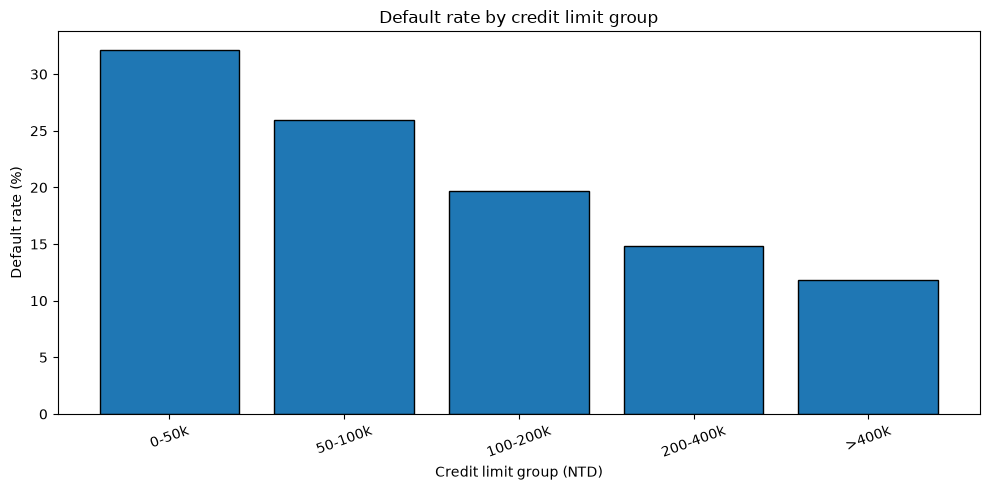

In [14]:
#visualizing default rates by credit limit group
plt.figure(figsize=(10, 5))
plt.bar(default_stats.index.astype(str), default_stats["default_rate_pct"], edgecolor="black")

plt.title("Default rate by credit limit group")
plt.xlabel("Credit limit group (NTD)")
plt.ylabel("Default rate (%)")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()


#### Observation of default rate by credit limit

- The default rate decreases as the credit limit increases.
- Clients with credit limits up to 50,000 NTD have
the highest observed default rate.
- Clients with credit limits above 400,000 NTD have
the lowest observed default rate.
- The relationship is consistently decreasing across
the five credit limit groups.

**Conclusion:**

The analysis suggests a negative association between
credit limits and default rates in the training data.

However, this does not imply causation. Clients with
higher credit limits may differ in other characteristics, such as their repayment history or financial situation.

In [15]:
#comparing group sizes and default rates

display(default_stats[["client_count", "default_count", "default_rate_pct"]])

,client_count,default_count,default_rate_pct
limit_group,,,
0-50k,6146,1977,32.17
50-100k,3819,990,25.92
100-200k,6350,1248,19.65
200-400k,6238,923,14.80
>400k,1447,171,11.82



#### Obsrevation of default rate by credit limit 

- Default rates decrease consistently as credit limits increase.
- The lowest credit limit group (0–50k NTD) has the
highest default rate of 32.17%.
- The highest credit limit group (>400k NTD) has the
lowest default rate of 11.82%.
- The difference between these groups is 20.35
percentage points.
- All groups contain more than 1,000 clients although the highest-limit group has fewer observations.

**Conclusion:**

Credit limit shows a negative association with default rates in the training dataset.

This relationship does not establish causation. Banks may assign higher credit limits to clients who already have a lower risk of default.
Credit limit may be a useful predictive feature, but
its contribution should be evaluated alongside other
client characteristics.



### 5.2 Default rate by repayment status

**Research question:**
How does a client's repayment status relate to
the probability of default in the following month?

We analyze PAY_0, which represents repayment
status in September 2005, using the training set.

In [16]:
#creating a dataFrame with repayment status and target
pay_df = X_train[["PAY_0"]].copy()
pay_df["DEFAULT"] = y_train

#calculating default statistics for each status
pay_stats = pay_df.groupby("PAY_0")["DEFAULT"].agg(client_count = "size", default_count = "sum", default_rate = "mean")

pay_stats["default_rate_pct"] = (pay_stats["default_rate"] * 100).round(2)
display(pay_stats)


,client_count,default_count,default_rate,default_rate_pct
PAY_0,,,,
-2,2198,279,0.126934,12.69
-1,4527,753,0.166335,16.63
0,11781,1508,0.128003,12.80
1,3000,1031,0.343667,34.37
2,2138,1483,0.693639,69.36
3,245,188,0.767347,76.73
4,58,38,0.655172,65.52
5,18,8,0.444444,44.44
6,10,6,0.600000,60.00


In [17]:
#checking sample sizes and default rates for PAY_0
display(pay_stats[["client_count", "default_count", "default_rate_pct"]])

,client_count,default_count,default_rate_pct
PAY_0,,,
-2,2198,279,12.69
-1,4527,753,16.63
0,11781,1508,12.80
1,3000,1031,34.37
2,2138,1483,69.36
3,245,188,76.73
4,58,38,65.52
5,18,8,44.44
6,10,6,60.00


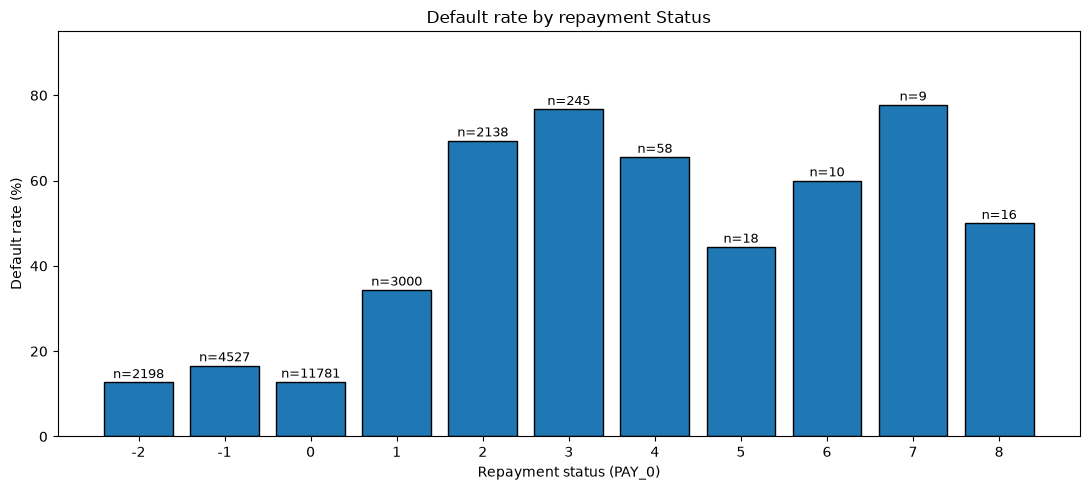

In [18]:
#default rate with sample size labels
fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(pay_stats.index.astype(str), pay_stats["default_rate_pct"], edgecolor="black")

#adding number of clients above each bar
for bar, count in zip(bars, pay_stats["client_count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, f"n={count}", ha="center", fontsize=9)

ax.set_title("Default rate by repayment Status")
ax.set_xlabel("Repayment status (PAY_0)")
ax.set_ylabel("Default rate (%)")
ax.set_ylim(0, 95)

plt.tight_layout()
plt.show()



#### Observation of default rate by repayment status

- Repayment status is strongly associated with default rates.
- Clients with PAY_0 values of -2, -1, and 0 have
relatively low observed default rates.
- Clients with PAY_0 = 2 or 3 have substantially
higher default rates.
- Categories with long repayment delays contain
very few observations.
- Default rates for rare categories are less reliable due to their small sample sizes.

**Conclusion:**

Repayment history appears to be a potentially
important predictor of credit default.

However, the relationship is not strictly monotonic,
and estimates for rare repayment categories should
be interpreted cautiously.
